# 电力时间序列：从 EDA 到 XGBoost 特征工程

独立中文学习 notebook，**原始 try.ipynb 和 CSV 均未修改**。按顺序 Run All；只依赖 CSV，以及 pandas、numpy、scikit-learn、xgboost、matplotlib，不依赖任何工作目录中间脚本。

前70%训练、中间15%验证、最后15%保留不评分。**验证段用于 early stopping 和方案比较，结果是探索性验证成绩，不是独立测试成绩，也不能证明已找到最佳模型。**这里重点是把第一部分观察转成第二部分可检验的特征假设。

## 1. 预测问题与信息集合

目标是 fossil gas；输入候选为 biomass、hydro water reservoir、solar、nuclear、wind onshore、fossil hard coal，以及已获允许的历史gas。

预测 $y_t$ 时，只使用截至 $t-1$ 的实测量和预先已知的 calendar$_t$。每小时获得新实测后再预测下一小时。这是**滚动一步预测**，并不是在验证期起点一次预测未来几个月。原 notebook 的 `future_target=0` 仍是一步预测，因为窗口最后一个观测是 $t-1$。

假定上一小时实测及时可得；有发布延迟时要进一步滞后。UTC保持连续小时轴，Europe/Madrid生成业务日历。不要删除时区后去重，夏令时会出现重复钟点及23/25小时本地日。

原 notebook 第一部分的 hydro water reservoir 是水库水电，不等于 pumped storage 抽水蓄能；两者物理含义需区分。将水库水电作为当前预测候选特征本身不是错误。

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
import sklearn
from xgboost import XGBRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.2})
print({'pandas':pd.__version__, 'numpy':np.__version__, 'xgboost':xgboost.__version__, 'sklearn':sklearn.__version__})
SOURCE=Path('energy_dataset.csv')
if not SOURCE.exists():
    SOURCE=Path('/Users/jiongwu/Documents/Python_Leetcode/Squarepoint/data-anlysis/energy_dataset.csv')
if not SOURCE.exists():
    raise FileNotFoundError('请把CSV放到当前目录，或修改SOURCE。')
NAMES=['biomass', 'hydro water reservoir', 'solar', 'nuclear', 'wind onshore', 'fossil hard coal']
data = pd.read_csv(SOURCE)
data.index = pd.DatetimeIndex(pd.to_datetime(data.pop('time'), utc=True))
data = data.sort_index()
assert data.index.equals(pd.date_range(data.index.min(), data.index.max(), freq='h'))
supply = data[['generation ' + c for c in NAMES + ['fossil gas']]].copy()
supply.columns = NAMES + ['fossil gas']
y = supply['fossil gas']
local = supply.index.tz_convert('Europe/Madrid')
n = len(data)
cut, end = int(n * .7), int(n * .85)

{'pandas': '2.3.3', 'numpy': '1.26.4', 'xgboost': '3.2.0', 'sklearn': '1.7.2'}


In [2]:
print('Train:', data.index[0], '→', data.index[cut-1])
print('Validation:', data.index[cut], '→', data.index[end-1])
print('Reserved test:', data.index[end], '→', data.index[-1], '(not scored)')
train_supply=supply.iloc[:cut].copy()
train_local=local[:cut]
audit=pd.DataFrame({'missing':train_supply.isna().sum(),'zeros':train_supply.eq(0).sum(),
                    'median':train_supply.median(),'max':train_supply.max()})
print('\nTraining-only audit:\n',audit.round(2).to_string())

Train: 2014-12-31 23:00:00+00:00 → 2017-10-19 14:00:00+00:00
Validation: 2017-10-19 15:00:00+00:00 → 2018-05-26 18:00:00+00:00
Reserved test: 2018-05-26 19:00:00+00:00 → 2018-12-31 22:00:00+00:00 (not scored)

Training-only audit:
                        missing  zeros  median      max
biomass                     18      0   381.0    592.0
hydro water reservoir       17      0  2097.0   9389.0
solar                       17      0   641.0   5792.0
nuclear                     16      0  6753.0   7116.0
wind onshore                17      0  4763.0  17436.0
fossil hard coal            17      0  4732.0   8359.0
fossil gas                  17      0  4820.0  20034.0


## 2. 用训练段 EDA 形成假设

solar是否同时有日周期与季节振幅？gas的日内形状是否随工作日/周末改变？不同变量的记忆长度是否相同？只看训练段形成假设，再在后续时间验证。相关性不是因果；低Pearson相关不代表没有非线性、条件作用。

Solar at local 00-04h: {'count': 5113.0, 'mean': 239.9, 'std': 257.47, 'min': 9.0, '25%': 35.0, '50%': 91.0, '75%': 471.0, 'max': 1374.0}
Positive: 5113 Zero: 0


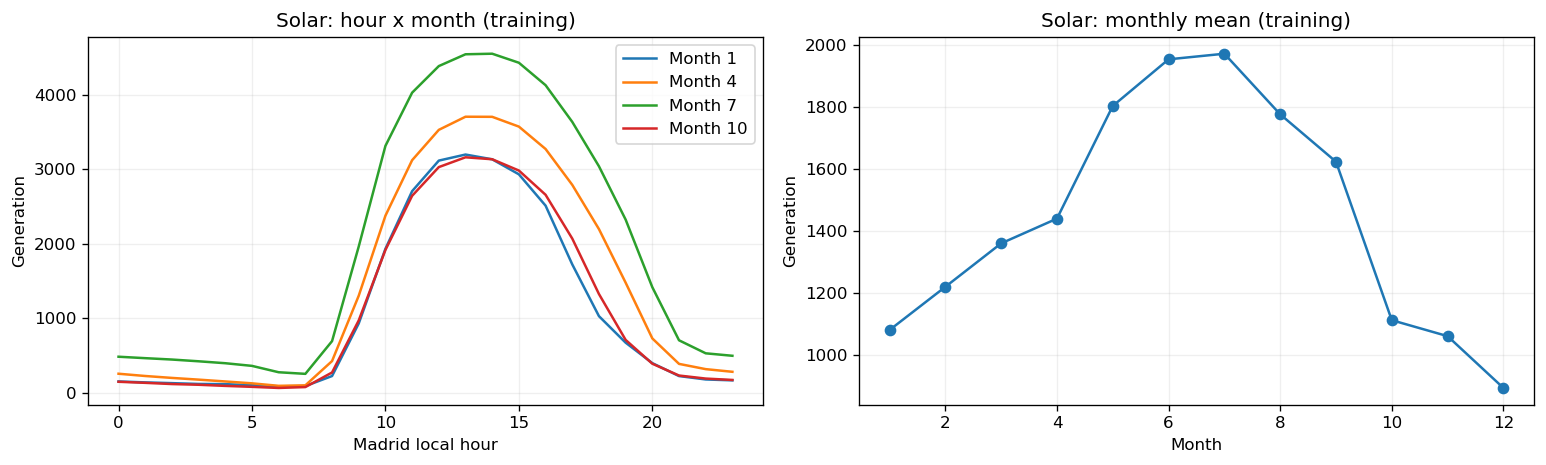

In [3]:
solar=train_supply['solar']; gas=train_supply['fossil gas']
fig,axes=plt.subplots(1,2,figsize=(13,4))
profile=solar.groupby([train_local.month,train_local.hour]).mean().unstack(0)
for month in [1,4,7,10]:
    axes[0].plot(profile.index,profile[month],label=f'Month {month}')
axes[0].set(title='Solar: hour x month (training)',xlabel='Madrid local hour',ylabel='Generation')
axes[0].legend()
solar.groupby(train_local.month).mean().plot(marker='o',ax=axes[1])
axes[1].set(title='Solar: monthly mean (training)',xlabel='Month',ylabel='Generation')
plt.tight_layout();plt.show()
night=solar[train_local.hour<=4]
print('Solar at local 00-04h:',night.describe().round(2).to_dict())
print('Positive:',int(night.gt(0).sum()),'Zero:',int(night.eq(0).sum()))

**观察→特征：**solar的日/年周期支持hour、month、cyclic编码及其交互；相同小时历史与相对典型曲线的偏差有助于区分“季节水平”和“今天偏离”。

训练段夜间solar仍为正，不要依据常识擅自置0，应核对字段定义。XGBoost并不要求输入正态或平稳；第一部分的分布变换不必自动搬到建模中。

Training-only lag correlations:
                          1      2      3      24     48     168
biomass                0.990  0.980  0.971  0.860  0.778  0.693
hydro water reservoir  0.940  0.824  0.697  0.736  0.613  0.441
solar                  0.952  0.827  0.658  0.869  0.821  0.736
nuclear                0.983  0.967  0.950  0.600  0.319  0.241
wind onshore           0.979  0.949  0.915  0.408  0.221  0.059
fossil hard coal       0.985  0.964  0.940  0.664  0.474  0.312
fossil gas             0.971  0.915  0.846  0.558  0.394  0.313

Contemporaneous correlation with gas:
 biomass                 -0.026
hydro water reservoir    0.037
solar                    0.083
nuclear                 -0.100
wind onshore            -0.412
fossil hard coal         0.534
fossil gas               1.000


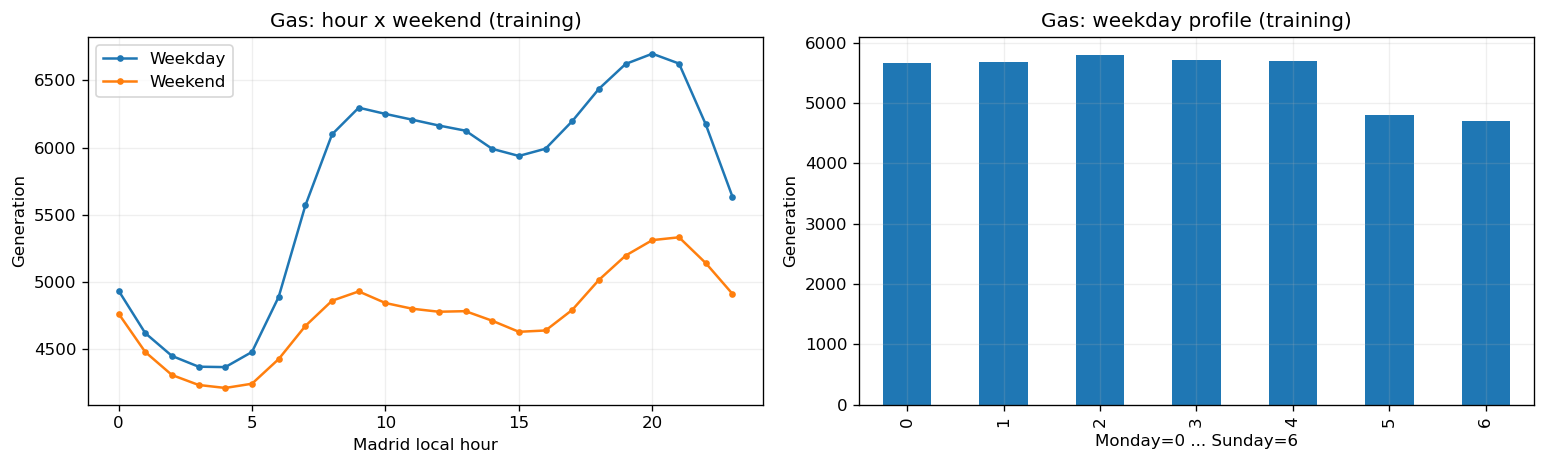

In [4]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
for weekend,label in [(False,'Weekday'),(True,'Weekend')]:
    mask=(train_local.dayofweek>=5)==weekend
    gas[mask].groupby(train_local[mask].hour).mean().plot(marker='.',ax=axes[0],label=label)
axes[0].set(title='Gas: hour x weekend (training)',xlabel='Madrid local hour',ylabel='Generation');axes[0].legend()
gas.groupby(train_local.dayofweek).mean().plot(kind='bar',ax=axes[1])
axes[1].set(title='Gas: weekday profile (training)',xlabel='Monday=0 ... Sunday=6',ylabel='Generation')
plt.tight_layout();plt.show()
lag_table=pd.DataFrame({col:{lag:train_supply[col].corr(train_supply[col].shift(lag))
                           for lag in [1,2,3,24,48,168]} for col in supply}).T
print('Training-only lag correlations:\n',lag_table.round(3).to_string())
print('\nContemporaneous correlation with gas:\n',train_supply.corr()['fossil gas'].round(3).to_string())

gas的高lag1相关提示必须比较“下一小时等于上一小时”。solar的lag24/168和wind的短期惯性可能不同，不能机械给所有列同样窗口。

缺失y不填补、不参与训练与评分；X保留NaN交给树。Ridge的填补只在训练段fit。极端值先调查，峰值可能是需要预测的事件，不按全样本分位数直接裁剪。

## 3. Cyclic construction 与原始窗口

周期$P$、位置$u$编码为 $\sin(2\pi u/P)$ 与 $\cos(2\pi u/P)$，两者共同表达相位。hour取24、weekday取7，年周期这里用365.25近似。只用sin会混淆不同相位。

XGBoost可直接分裂raw hour/month，不强制sin/cos；线性模型更需要合适的周期基函数。这里保留raw与一阶cyclic，随后加高阶Fourier。business hour只是hour的粗分箱，没有增加新信息。

A复制原240列结构：10变量×过去24小时。XGBoost把各滞后视为普通列，没有自动理解序列顺序。

In [5]:
# Match the notebook's lag expansion, but preserve missing feature values.
base = supply[NAMES].copy()
base['hour'] = local.hour
base['weekday'] = local.dayofweek
base['month'] = local.month
h = local.hour
base['business hour'] = np.select([(h > 8) & (h < 14) | (h > 16) & (h < 21), (h >= 14) & (h <= 16)], [2, 1], 0)
flat = pd.concat({f'lag{lag}': base.shift(lag) for lag in range(1, 25)}, axis=1)
flat.columns = [f'{c}_{lag}' for lag, c in flat.columns]

calendar = pd.DataFrame({'hour': h, 'weekday': local.dayofweek, 'month': local.month,
                         'dayofyear': local.dayofyear, 'weekend': (local.dayofweek >= 5).astype(int)}, index=data.index)
for name, values, period in [('hour', h, 24), ('weekday', local.dayofweek, 7), ('annual', local.dayofyear - 1, 365.25)]:
    calendar[name + '_sin'] = np.sin(2 * np.pi * values / period)
    calendar[name + '_cos'] = np.cos(2 * np.pi * values / period)

## 4. 少量lag、rolling、ramp与gas历史

C取lag1/2/3/24/48/168，加目标时刻calendar；D加过去3/24/168小时均值和标准差、短时ramp、24小时变化、近期均值偏差；E再加入gas历史。rolling必须先shift，不能包含目标时刻实测。

所有方案统一从pos168开始，按标签时间划分。验证首小时可以使用训练末尾的已知历史，不必在每个边界再丢168行。

In [6]:
def lag_features(frame):
    out = {}
    for col in frame:
        for lag in [1, 2, 3, 24, 48, 168]:
            out[f'{col}_lag{lag}'] = frame[col].shift(lag)
    return pd.DataFrame(out, index=data.index)

def summaries(frame):
    out = {}
    for col in frame:
        s = frame[col]
        past = s.shift(1)
        for window in [3, 24, 168]:
            rolling = past.rolling(window, min_periods=window)
            out[f'{col}_mean{window}'] = rolling.mean()
            out[f'{col}_std{window}'] = rolling.std()
        out[f'{col}_ramp1'] = s.shift(1) - s.shift(2)
        out[f'{col}_change24'] = s.shift(1) - s.shift(25)
        out[f'{col}_deviation24'] = past - past.rolling(24).mean()
    return pd.DataFrame(out, index=data.index)

compact = pd.concat([lag_features(supply[NAMES]), calendar], axis=1)
engineered = pd.concat([compact, summaries(supply[NAMES])], axis=1)
renewable = supply[['solar', 'wind onshore']].sum(axis=1, min_count=2)
non_gas = supply[NAMES].sum(axis=1, min_count=len(NAMES))
engineered['wind_solar_sum_lag1'] = renewable.shift(1)
engineered['selected_non_gas_sum_lag1'] = non_gas.shift(1)
engineered['wind_solar_share_lag1'] = renewable.shift(1) / non_gas.shift(1).replace(0, np.nan)
with_y = pd.concat([engineered, lag_features(supply[['fossil gas']]), summaries(supply[['fossil gas']])], axis=1)

In [7]:
gas_history=pd.concat([lag_features(supply[['fossil gas']]),summaries(supply[['fossil gas']])],axis=1)
gas_only=pd.concat([gas_history,calendar],axis=1)
print(pd.Series({'A_flat24':flat.shape[1],'C_compact':compact.shape[1],
                 'D_summary':engineered.shape[1],'E_gas_history':with_y.shape[1],
                 'H_gas_only':gas_only.shape[1]},name='Number of features').to_string())

A_flat24         240
C_compact         47
D_summary        104
E_gas_history    119
H_gas_only        26


`wind_solar_share_lag1`的分母是所选六种供电之和，不是系统总发电量。高度相关的lag和rolling可能冗余，更多列不保证更好；H只用gas历史+calendar，检查其他供电是否有额外价值。

## 5. 从EDA到额外特征L

- 二、三阶日内Fourier允许更复杂的日内形状；与weekend相乘允许周末曲线不同。
- 过去7天“同小时”均值描述近期周期水平；这里是24个真实小时的倍数，DST附近不是严格相同当地钟点。
- solar month×hour profile仅在当前fold训练段估计，生成目标小时典型值、上一小时的观测偏差。

训练行使用整段训练统计是训练期拟合变换，类似scaler；它不是gas目标编码。模拟历史在线更新时，需按每次训练起点重估，不能用验证段拟合profile。

In [8]:
fourier = with_y.copy()
for k in [2, 3]:
    for trig, func in [('sin', np.sin), ('cos', np.cos)]:
        fourier[f'hour_{trig}_{k}'] = func(2*np.pi*k*local.hour/24)
for k in [1, 2, 3]:
    for trig, func in [('sin', np.sin), ('cos', np.cos)]:
        fourier[f'weekend_hour_{trig}_{k}'] = (local.dayofweek >= 5) * func(2*np.pi*k*local.hour/24)

seasonal_history = fourier.copy()
for col in ['fossil gas', 'solar', 'hydro water reservoir']:
    s = supply[col]
    # All 7 inputs are at least 24 real hours old. DST handling remains a separate choice.
    same_hour = pd.concat([s.shift(24*k) for k in range(1, 8)], axis=1).mean(axis=1)
    seasonal_history[f'{col}_same_hour_7d_mean'] = same_hour
    seasonal_history[f'{col}_lag1_minus_same_hour_recent'] = s.shift(1) - same_hour.shift(1)

def solar_profiles(a):
    # Fitted ONLY on the training slice for this fold, never all four years.
    x = supply['solar'].iloc[:a]
    ix = local[:a]
    lookup = x.groupby([ix.month, ix.hour]).mean()
    def lookup_at(index):
        keys = pd.MultiIndex.from_arrays([index.month, index.hour])
        return pd.Series(lookup.reindex(keys).to_numpy(), index=data.index)
    typical_now = lookup_at(local)
    typical_previous = lookup_at((data.index - pd.Timedelta(hours=1)).tz_convert('Europe/Madrid'))
    X = seasonal_history.copy()
    X['solar_typical_at_target_hour'] = typical_now
    X['solar_anomaly_lag1'] = supply['solar'].shift(1) - typical_previous
    return X

## 6. 固定协议训练与比较

先建立naive基线；XGBoost采用浅树、适度正则和早停。参数只是教学起点，不是最优搜索结果。

Ridge先学习 $\hat y^{\mathrm{lin}}$，XGBoost学习训练残差 $r=y-\hat y^{\mathrm{lin}}$，预测时相加。这是两阶段加法模型；若训练stacking的第二层，则需要按时间生成的OOF预测，不能用过于乐观的in-sample预测。

树不需要标准化；Ridge的median、missing indicator、scaler都只fit训练段。

本实验的Ridge使用完整E/L特征（119/137列，包含lag、rolling等），并不是只拟合calendar/Fourier的季节基线；仅用周期基函数拟合平滑季节项，可另设一个尚未验证的对照实验。

In [9]:
params = dict(objective='reg:squarederror', tree_method='hist', n_estimators=1600,
              learning_rate=.04, max_depth=4, min_child_weight=10,
              subsample=.8, colsample_bytree=.8, reg_lambda=10., reg_alpha=.1,
              eval_metric='rmse', early_stopping_rounds=80, random_state=42, n_jobs=4)

rows,predictions,models=[],{},{}
def scores(true,pred):
    return {'rmse':float(np.sqrt(mean_squared_error(true,pred))),'mae':float(mean_absolute_error(true,pred))}
def masks(a,b):
    pos=np.arange(n)
    return ((pos>=168)&(pos<a)&y.notna().values,(pos>=a)&(pos<b)&y.notna().values)
def fit_model(name,X,a,b,fold='main',kind='xgb'):
    train,valid=masks(a,b)
    xt,xv,yt,yv=X.loc[train],X.loc[valid],y.loc[train],y.loc[valid]
    started=time.monotonic();margin_t=np.zeros(len(yt));margin_v=np.zeros(len(yv))
    linear,model=None,None
    if kind in ['ridge','ridge+xgb']:
        linear=make_pipeline(SimpleImputer(strategy='median',add_indicator=True),StandardScaler(),Ridge(alpha=100.))
        linear.fit(xt,yt);margin_t,margin_v=linear.predict(xt),linear.predict(xv)
    if kind!='ridge':
        model=XGBRegressor(**params)
        model.fit(xt,yt-margin_t,eval_set=[(xv,yv-margin_v)],verbose=False)
        pt,pv=model.predict(xt)+margin_t,model.predict(xv)+margin_v
        best=int(model.best_iteration+1)
    else:
        pt,pv,best=margin_t,margin_v,None
    row=dict(fold=fold,name=name,model=kind,n_features=X.shape[1],n_train=len(yt),n_valid=len(yv),
             train_rmse=scores(yt,pt)['rmse'],best_round=best,seconds=round(time.monotonic()-started,2),**scores(yv,pv))
    rows.append(row)
    print(f"{fold:12} {name:32} RMSE={row['rmse']:8.2f} MAE={row['mae']:7.2f} best={best}")
    if fold=='main':
        predictions[name]=pd.Series(pv,index=yv.index)
        models[name]={'linear':linear,'xgb':model,'columns':list(X.columns)}
    return row
def baselines(a,b,fold='main',lags=(1,24,168)):
    train,valid=masks(a,b)
    for lag in lags:
        pred=y.ffill().shift(lag).loc[valid]
        row=dict(fold=fold,name=f'naive_lag{lag}',model='naive',n_features=1,
                 n_train=int(train.sum()),n_valid=int(valid.sum()),**scores(y.loc[valid],pred))
        rows.append(row)
        if fold=='main':predictions[row['name']]=pred
        print(f"{fold:12} {row['name']:32} RMSE={row['rmse']:8.2f} MAE={row['mae']:7.2f}")

In [10]:
main_specs=[
 ('A_flat24',flat,'xgb'),('C_compact_lags_calendar',compact,'xgb'),
 ('D_plus_summary_features',engineered,'xgb'),('E_plus_target_history',with_y,'xgb'),
 ('H_gas_history_calendar_only',gas_only,'xgb'),('E_ridge',with_y,'ridge'),
 ('E_ridge_plus_xgb',with_y,'ridge+xgb'),('L_eda_xgb',solar_profiles(cut),'xgb'),
 ('L_eda_ridge_plus_xgb',solar_profiles(cut),'ridge+xgb')]
rows,predictions,models=[],{},{}
baselines(cut,end)
for name,X,kind in main_specs:
    fit_model(name,X,cut,end,kind=kind)
main_results=pd.DataFrame(rows)
print('\nMain validation comparison:\n',main_results[['name','n_features','train_rmse','rmse','mae','best_round']].round(2).to_string(index=False))

main         naive_lag1                       RMSE=  653.67 MAE= 373.86
main         naive_lag24                      RMSE= 2206.34 MAE=1487.25
main         naive_lag168                     RMSE= 2940.94 MAE=2084.71
main         A_flat24                         RMSE= 1544.57 MAE=1061.01 best=302
main         C_compact_lags_calendar          RMSE= 1672.13 MAE=1112.12 best=293
main         D_plus_summary_features          RMSE= 1486.40 MAE=1021.49 best=1598
main         E_plus_target_history            RMSE=  444.21 MAE= 265.97 best=811
main         H_gas_history_calendar_only      RMSE=  443.37 MAE= 271.52 best=517
main         E_ridge                          RMSE=  469.98 MAE= 293.53 best=None
main         E_ridge_plus_xgb                 RMSE=  376.40 MAE= 244.71 best=966
main         L_eda_xgb                        RMSE=  437.52 MAE= 263.71 best=1058
main         L_eda_ridge_plus_xgb             RMSE=  371.80 MAE= 243.29 best=1165

Main validation comparison:
                      

### 如何解读消融

看C是否优于A、D是否稳定改善C、E加gas历史有多大收益、H小模型是否已接近E、组合是否优于单模型。原 notebook旧日志与A的参数/填补不同，不能把差值归因于某一个改动。

既有相同脚本实验的主验证参考：H仅26列XGB RMSE约443.37，与E119列444.21相近；E组合376.40；L137列XGB437.52、L组合371.80。gas-only组合在额外检查中约377.77（为减少重复拟合，本notebook不重跑该项）。这些数字说明：**历史gas贡献很大，额外堆特征的边际改善较小**。运行结果可能随库版本略变，以当前输出为准。

L一次加入多个相关特征组，不能把整体收益都归功于某个Fourier项。近似误差时应考虑简洁性、稳定性与可解释性。

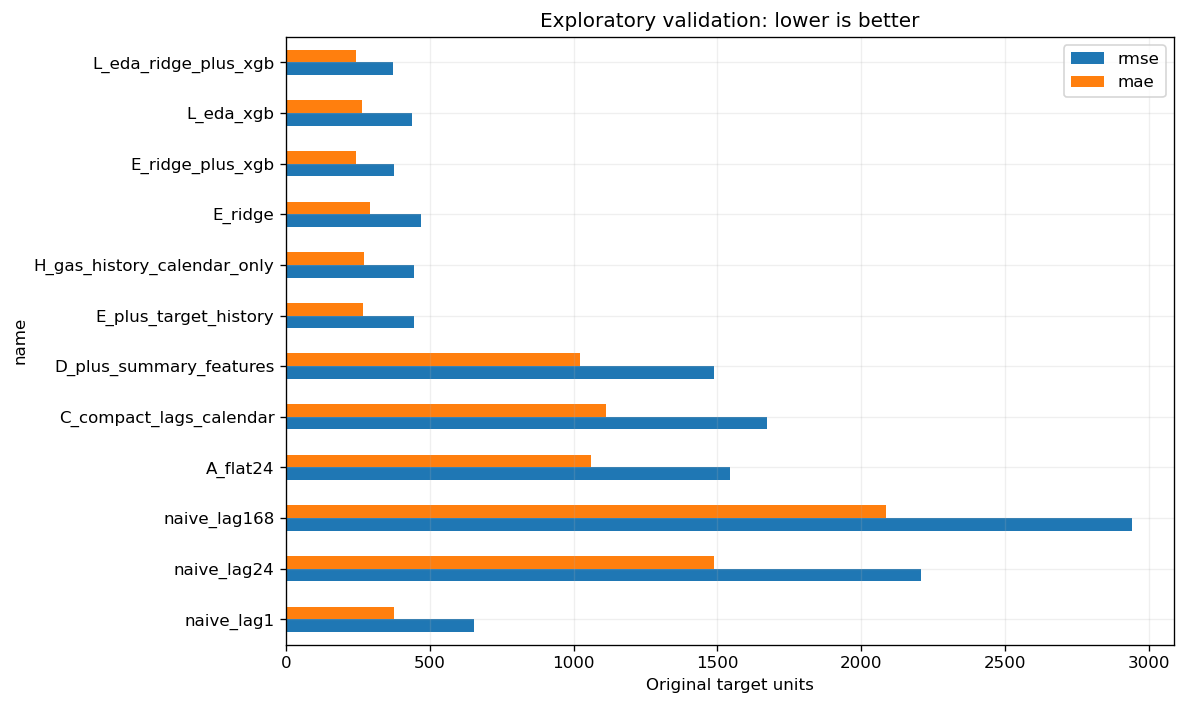

In [11]:
main_results.set_index('name')[['rmse','mae']].plot(kind='barh',figsize=(10,6))
plt.title('Exploratory validation: lower is better');plt.xlabel('Original target units')
plt.tight_layout();plt.show()

## 7. 两个更早的时间窗口

比较前50%→后10%、前60%→后10%的expanding验证。每fold重训，solar profile也必须重估。它们检查稳定性，仍是开发阶段，不是nested无偏评估。

既有L组合参考RMSE约385.23/361.13；不能只凭三个窗口便宣布全局最优。模型与规则冻结后才能评价保留测试段，本notebook不执行。

In [12]:
rows=[r for r in rows if r['fold']=='main']
for fraction in [.5,.6]:
    a,b=int(n*fraction),int(n*(fraction+.1));fold=f'earlier_{fraction:.1f}'
    baselines(a,b,fold,lags=(1,))
    fit_model('E_plus_target_history',with_y,a,b,fold)
    fit_model('E_ridge_plus_xgb',with_y,a,b,fold,kind='ridge+xgb')
    fit_model('L_eda_ridge_plus_xgb',solar_profiles(a),a,b,fold,kind='ridge+xgb')
results=pd.DataFrame(rows)
selected=results[results['name'].isin(['naive_lag1','E_plus_target_history','E_ridge_plus_xgb','L_eda_ridge_plus_xgb'])]
print(selected.pivot(index='name',columns='fold',values='rmse').round(2).to_string())

earlier_0.5  naive_lag1                       RMSE=  594.18 MAE= 306.96
earlier_0.5  E_plus_target_history            RMSE=  537.47 MAE= 257.41 best=794
earlier_0.5  E_ridge_plus_xgb                 RMSE=  391.84 MAE= 229.45 best=928
earlier_0.5  L_eda_ridge_plus_xgb             RMSE=  385.23 MAE= 228.26 best=1065
earlier_0.6  naive_lag1                       RMSE=  598.30 MAE= 369.16
earlier_0.6  E_plus_target_history            RMSE=  395.55 MAE= 265.96 best=402
earlier_0.6  E_ridge_plus_xgb                 RMSE=  373.88 MAE= 248.41 best=531
earlier_0.6  L_eda_ridge_plus_xgb             RMSE=  361.13 MAE= 241.82 best=1223
fold                   earlier_0.5  earlier_0.6    main
name                                                   
E_plus_target_history       537.47       395.55  444.21
E_ridge_plus_xgb            391.84       373.88  376.40
L_eda_ridge_plus_xgb        385.23       361.13  371.80
naive_lag1                  594.18       598.30  653.67


## 8. 残差诊断驱动下一轮特征工程

演示L组合，不代表它已被独立测试证明最好。残差=actual−prediction，正偏差表示低估。检查小时RMSE、小时偏差、残差ACF及局部曲线。高小时误差可能来自真实波动较大；lag24结构提示进一步检查周期特征；峰值低估提示检查需求信号、ramp和损失函数。诊断只是新假设，仍需验证。

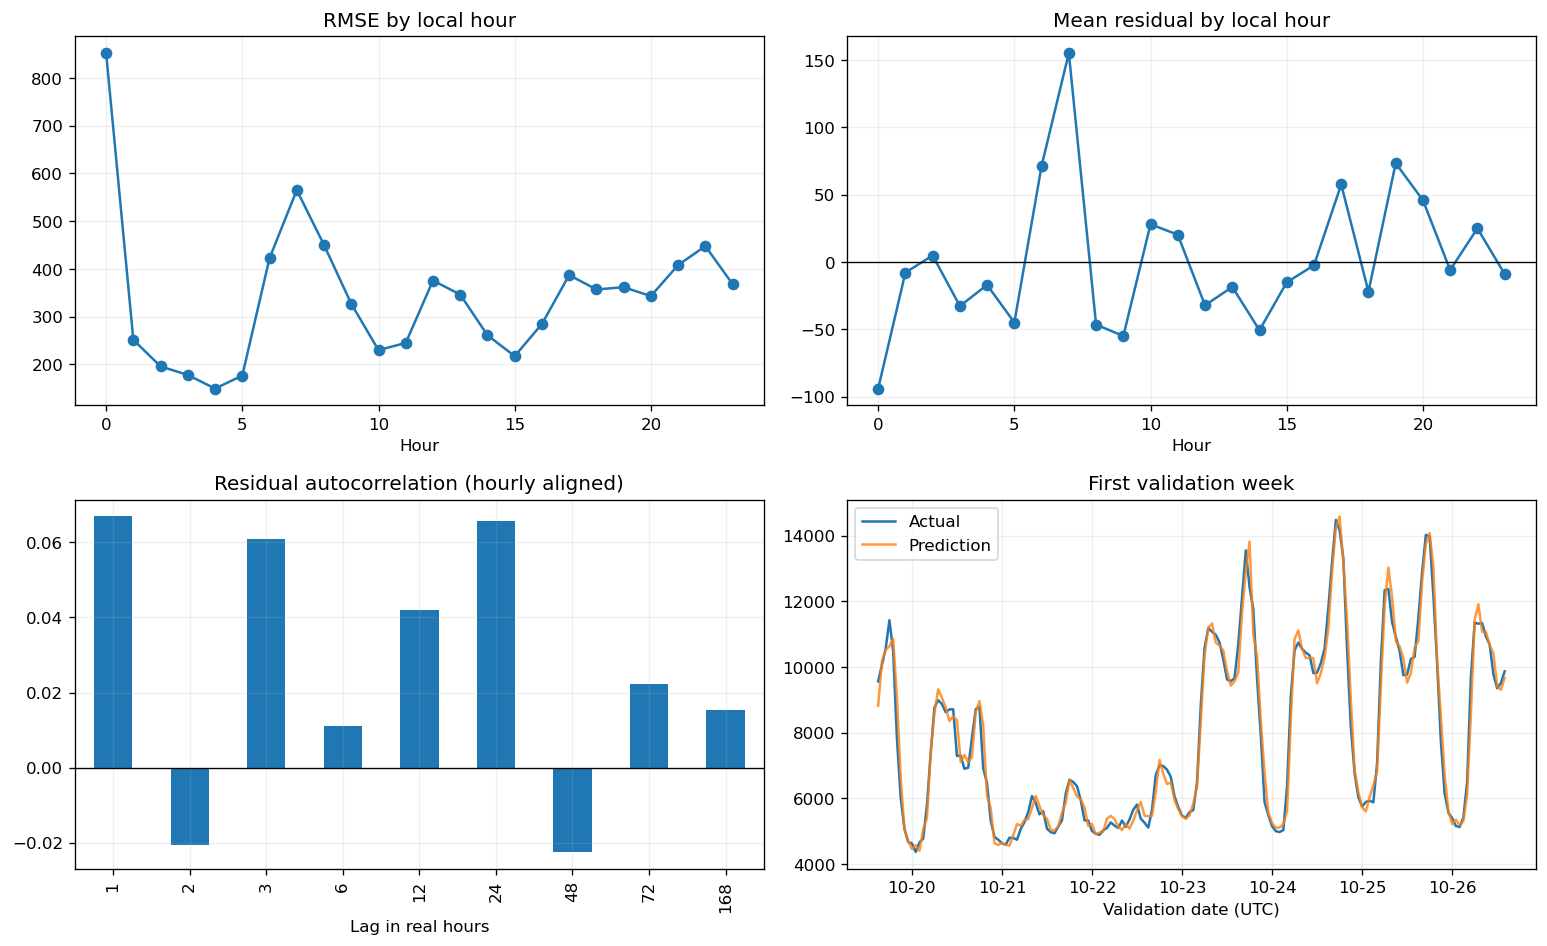

Validation bias: 1.2
Residual ACF:
 1      0.067
2     -0.021
3      0.061
6      0.011
12     0.042
24     0.066
48    -0.022
72     0.022
168    0.015


In [13]:
import matplotlib.dates as mdates
diagnostic_name='L_eda_ridge_plus_xgb'
val_index=data.index[cut:end]
observed=y.reindex(val_index);predicted=predictions[diagnostic_name].reindex(val_index)
residual=observed-predicted
hour=val_index.tz_convert('Europe/Madrid').hour
hour_rmse=residual.pow(2).groupby(hour).mean().pow(.5)
hour_bias=residual.groupby(hour).mean()
acf=pd.Series({lag:residual.autocorr(lag) for lag in [1,2,3,6,12,24,48,72,168]})
fig,axes=plt.subplots(2,2,figsize=(13,8))
hour_rmse.plot(marker='o',ax=axes[0,0]);axes[0,0].set(title='RMSE by local hour',xlabel='Hour')
hour_bias.plot(marker='o',ax=axes[0,1]);axes[0,1].axhline(0,color='black',linewidth=.8)
axes[0,1].set(title='Mean residual by local hour',xlabel='Hour')
acf.plot(kind='bar',ax=axes[1,0]);axes[1,0].axhline(0,color='black',linewidth=.8)
axes[1,0].set(title='Residual autocorrelation (hourly aligned)',xlabel='Lag in real hours')
axes[1,1].plot(observed.iloc[:168].index,observed.iloc[:168],label='Actual')
axes[1,1].plot(predicted.iloc[:168].index,predicted.iloc[:168],label='Prediction',alpha=.8)
axes[1,1].set(title='First validation week');axes[1,1].legend()
axes[1,1].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
axes[1,1].set_xlabel('Validation date (UTC)')
plt.tight_layout();plt.show()
print('Validation bias:',round(residual.mean(),2));print('Residual ACF:\n',acf.round(3).to_string())

## 9. 特征重要性与分组消融

gain重要性不表示因果。相关lag/rolling会分摊重要性，低重要性不等于没有信息。下面显示的只是**组合模型中残差XGBoost部分**，不是整个组合的重要性。

优先做分组消融：移除全部gas历史、其他供电、calendar/周期项，观察验证差异。Permutation需注意时间结构和相关变量，随机打乱单列可能制造不真实组合。

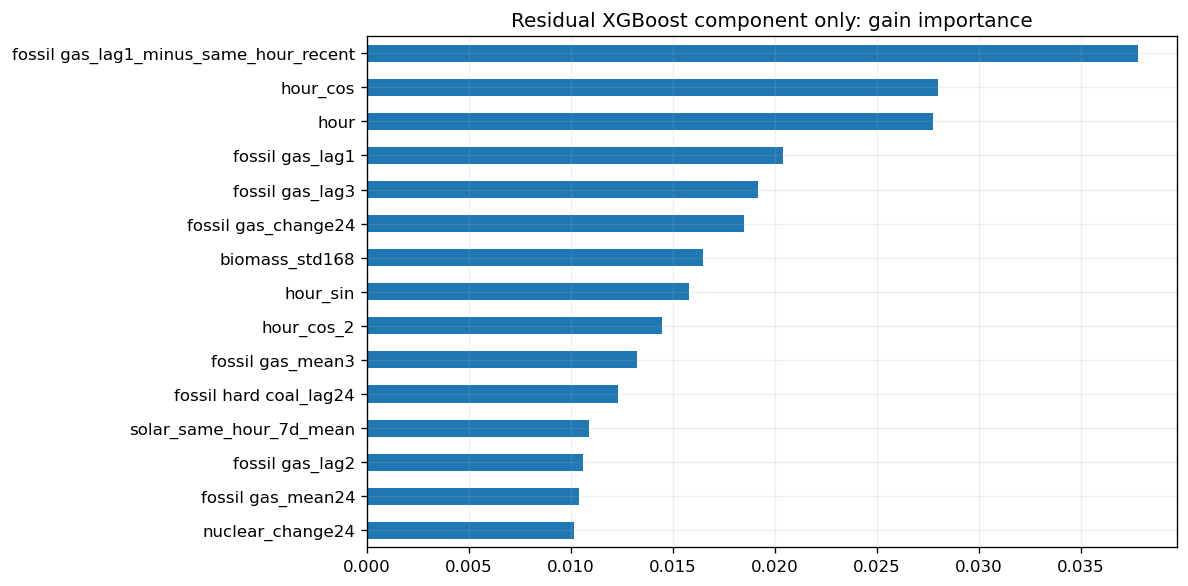

In [14]:
saved=models[diagnostic_name]
importance=pd.Series(saved['xgb'].feature_importances_,index=saved['columns']).sort_values()
importance.tail(15).plot(kind='barh',figsize=(10,5))
plt.title('Residual XGBoost component only: gain importance');plt.tight_layout();plt.show()

## 10. 未在此验证的扩展练习

1. **季节差分目标**：预测 $z_t=y_t-y_{t-24}$，再加回 $y_{t-24}$，在原始gas尺度评价。日差不是自动有效，可能放大噪声。下一格只是对齐示例，不训练新模型。
2. **高阶Fourier、periodic spline**：更高阶或更多结点能拟合复杂周期，也更易过拟合；由时间验证选择。树对训练区间外的趋势值不擅长外推。
3. **Expanding / sliding window**：全部历史增加样本，滑动近期窗口适应漂移；比较窗口长度、重训频率和近期样本权重。
4. **gap不是最大lag**：lag168不意味着必须空168小时。一步预测且标签及时可得，边界历史可以使用；gap应由未来标签窗口重叠、发布延迟和业务隔离期决定。
5. **direct / recursive多步预测**：direct按h训练未来目标；recursive把预测值喂回未来gas lag。一次预测24小时不能使用中途真实gas或未来实测供电；calendar可预知。
6. **forecast列的发布时间**：day-ahead forecast只有在预测起点已发布且历史版本可追溯时才可用。列名本身不能证明无泄漏。节假日、检修安排和负荷预测也一样。
7. **回顾性分析≠在线特征**：全样本分解、centered rolling、双向插值、当天未结束就使用当天总量，都可能引入未来。seasonal_decompose默认双侧滤波，不能直接把全样本分解结果当在线预测特征。
8. **DST与同小时历史**：24个真实小时与昨日相同当地钟点在DST附近不同，需按任务决定；不要删除timezone来绕开问题。

每次只变一组合理特征，用相同目标时点比较，记录误差、复杂度、数据可用性和各窗口稳定性。

In [15]:
# Seasonal target differencing: alignment example only; no new model is fitted.
demo_y=y.iloc[:cut]
seasonal_base=demo_y.shift(24)
z=demo_y-seasonal_base
reconstructed=z+seasonal_base
valid_reconstruction=demo_y.notna()&seasonal_base.notna()
assert np.allclose(reconstructed[valid_reconstruction],demo_y[valid_reconstruction])
print('Predict z_t, then reconstruct: y_hat_t = z_hat_t + y_(t-24).')
print('Train only where z is observed; score reconstructed predictions in original units.')

Predict z_t, then reconstruct: y_hat_t = z_hat_t + y_(t-24).
Train only where z is observed; score reconstructed predictions in original units.


## 11. 官方/维护者阅读资料

- [scikit-learn：周期特征工程](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html)：比较raw calendar、三角编码与周期样条，理解线性模型和树对编码需求的差异。
- [skforecast维护者：电力负荷预测](https://cienciadedatos.net/documentos/py29-forecasting-electricity-power-demand-python.html)：学习从EDA到滞后、日历、回测与解释的完整流程，不直接照搬数据和参数。
- [Nixtla MLForecast：电力负荷预测](https://nixtlaverse.nixtla.io/mlforecast/docs/tutorials/electricity_load_forecasting.html)：学习组织滞后、时间特征和预测流程；本例用pandas显式构造以看清对齐。
- [statsmodels：seasonal_decompose](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.seasonal_decompose.html)：核对滤波方向、周期和边界，区分回顾性分解与预测时可用特征。

实验记录应包含预测horizon、可用字段、训练/验证日期、特征组、随机种子、库版本及诊断。保留最后15%测试段，待方案冻结后再评价。